# 01 · Exploratory data analysis — what does an Ames house price depend on?

**Problem.** Given the physical description of a house sold in Ames, Iowa (79 features), predict its sale price, and say how sure we are.

**Why it matters.** A price estimate with an honest error bar is useful to a buyer, a seller or an appraiser; one without is a guess.

**How we will judge it.** Prices span almost two orders of magnitude, and a \$20k miss on a \$60k home is far worse than on a \$600k home. So the metric is **RMSLE**, the RMSE of `log(1 + price)` (the Kaggle metric for this data). It measures *relative* error: RMSLE 0.12 is roughly a typical 12 % miss.

This notebook answers four questions that drive every later modelling choice:

1. What does the target look like, and should we transform it?
2. What do the many missing values *mean*?
3. Which features carry the signal?
4. Are there data-quality traps (outliers, time effects)?

Nothing here is fitted on a hold-out set; the 20 % hold-out split is carved off in notebook 02 and is not looked at until notebook 03.

In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"   # also silences joblib worker processes
import time, warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from IPython.display import Markdown, display

from housing import config, data
from housing import plotting as P
from housing.features import ABSENCE_RULES, AmesFeatureBuilder

P.set_style()
pd.set_option("display.max_columns", 30, "display.width", 140)
T0 = time.perf_counter()

df = data.load_data()
if config.SMOKE:
    df = data.smoke_subsample(df)
X, y = data.split_xy(df)
print(f"{len(df):,} houses x {X.shape[1]} features | smoke mode: {config.SMOKE}")

1,460 houses x 79 features | smoke mode: False


## Data card (short version)

| | |
|---|---|
| **What** | Residential home sales in **Ames, Iowa**, with 79 descriptors (size, quality, age, location, condition of sale). |
| **Source** | Ames Housing dataset compiled by Dean De Cock (2011, *Journal of Statistics Education*); mirrored on OpenML as `house_prices` (id 42165), no login needed. |
| **Rows** | 1,460 sales (the labelled "train" half of the Kaggle competition split). |
| **Period** | Sold 2006–2010, i.e. through the US housing crash. |
| **Licence** | OpenML lists *no licence* ("NA"); the original is published for education. The data is **not redistributed** in this repo; `make data` downloads it. Full notes in `docs/DATA_CARD.md`. |

In [2]:
summary = pd.DataFrame({
    "numeric features": [X.select_dtypes("number").shape[1]],
    "categorical features": [X.select_dtypes(exclude="number").shape[1]],
    "sales years": [f"{int(df.YrSold.min())}-{int(df.YrSold.max())}"],
    "duplicate rows": [int(df.drop(columns="Id").duplicated().sum())],
    "price range": [f"${df.SalePrice.min():,.0f} - ${df.SalePrice.max():,.0f}"],
    "median price": [f"${df.SalePrice.median():,.0f}"],
}, index=["value"]).T
summary

,value
numeric features,36
categorical features,43
sales years,2006-2010
duplicate rows,0
price range,"$34,900 - $755,000"
median price,"$163,000"


## 1 · The target: prices are right-skewed, errors are proportional

The histogram on the left is the classic shape of money: a long right tail. Taking logs (right) makes it close to symmetric. That matters for three practical reasons, shown below the plot:

* the evaluation metric (RMSLE) *is* RMSE on the log scale, so training on the log target optimises the thing we are judged on;
* a house costing 20 % more tends to be 20 % more *off*, not \$X more off, so errors are multiplicative;
* linear models assume similar error variance everywhere (homoscedasticity), which only holds after the transform.

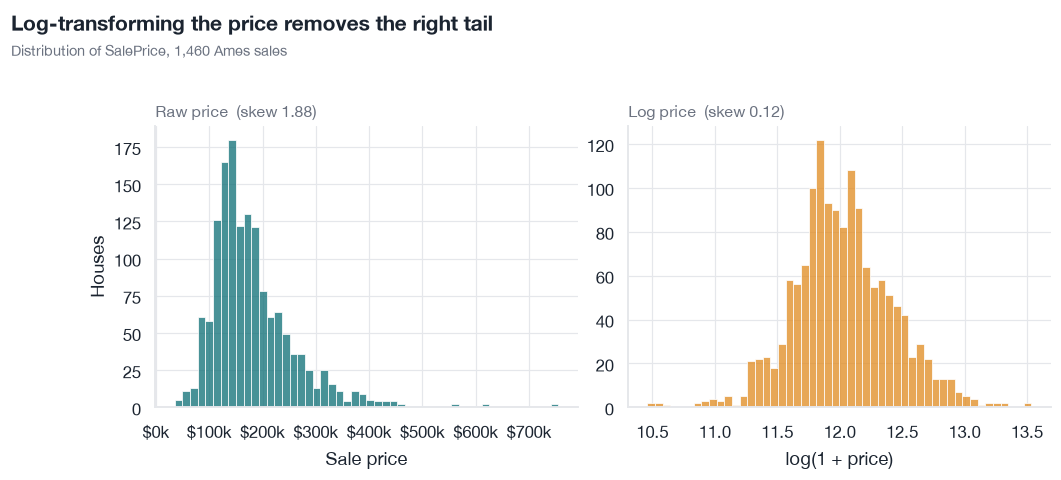

In [3]:
sk_raw, sk_log = stats.skew(y), stats.skew(np.log1p(y))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
sns.histplot(y, bins=50, color=P.TEAL, edgecolor="white", ax=axes[0])
axes[0].xaxis.set_major_formatter(P.usd); axes[0].set(xlabel="Sale price", ylabel="Houses")
axes[0].set_title(f"Raw price  (skew {sk_raw:.2f})", loc="left", fontsize=10.5, color=P.MUTED, fontweight="normal")
sns.histplot(np.log1p(y), bins=50, color=P.AMBER, edgecolor="white", ax=axes[1])
axes[1].set(xlabel="log(1 + price)", ylabel="")
axes[1].set_title(f"Log price  (skew {sk_log:.2f})", loc="left", fontsize=10.5, color=P.MUTED, fontweight="normal")
P.fig_headline(fig, "Log-transforming the price removes the right tail", "Distribution of SalePrice, 1,460 Ames sales", y=0.99)
fig.subplots_adjust(top=0.82, wspace=0.12)
P.save_fig(fig, "eda_target_log"); plt.show()

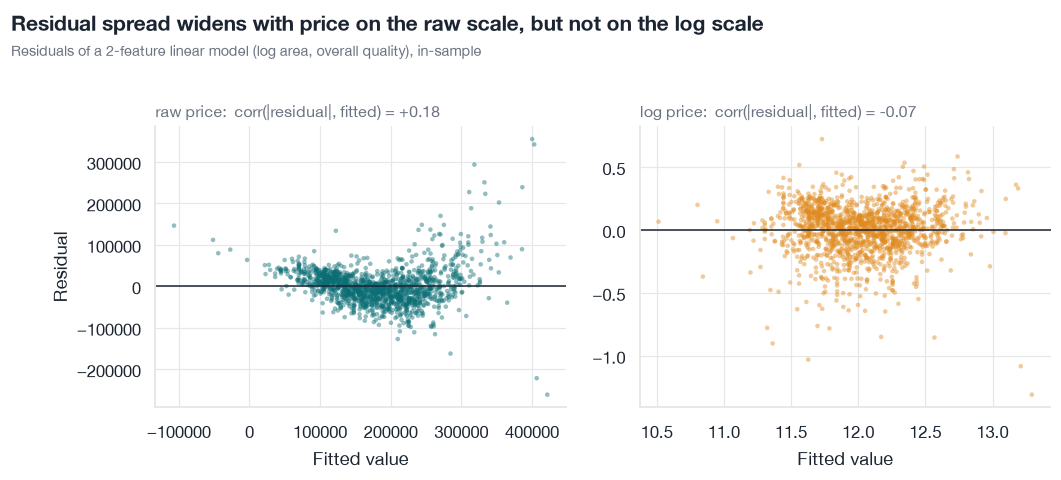

**Decision:** model `log1p(SalePrice)` everywhere. Error-vs-level correlation drops from +0.18 to -0.07.

In [4]:
# Heteroscedasticity illustration: same two predictors, raw vs log target (in-sample, EDA only).
from sklearn.linear_model import LinearRegression
Z = pd.DataFrame({"log_area": np.log1p(X.GrLivArea), "qual": X.OverallQual})
res = {}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=False)
for ax, (label, target, colour) in zip(axes, [("raw price", y.to_numpy(), P.TEAL), ("log price", np.log1p(y).to_numpy(), P.AMBER)], strict=True):
    lm = LinearRegression().fit(Z, target)
    fitted, resid = lm.predict(Z), target - lm.predict(Z)
    res[label] = stats.spearmanr(fitted, np.abs(resid)).statistic
    ax.scatter(fitted, resid, s=9, alpha=0.45, color=colour, edgecolor="none")
    ax.axhline(0, color=P.INK, lw=1)
    ax.set_title(f"{label}:  corr(|residual|, fitted) = {res[label]:+.2f}", loc="left", fontsize=10.5, color=P.MUTED, fontweight="normal")
    ax.set_xlabel("Fitted value")
axes[0].set_ylabel("Residual")
P.fig_headline(fig, "Residual spread widens with price on the raw scale, but not on the log scale", "Residuals of a 2-feature linear model (log area, overall quality), in-sample", y=0.99)
fig.subplots_adjust(top=0.82, wspace=0.18)
plt.show()
display(Markdown(f"**Decision:** model `log1p(SalePrice)` everywhere. Error-vs-level correlation drops from {res['raw price']:+.2f} to {res['log price']:+.2f}."))

## 2 · Missing values: in Ames, `NaN` usually means *"this house has no such thing"*

A generic pipeline (`SimpleImputer(strategy="most_frequent")`, as in the notebook this repo started from) would fill 1,453 missing `PoolQC` entries with whatever the most common pool quality is, inventing swimming pools for 99.5 % of houses. The data dictionary says otherwise: `NA` = *no pool*.

We check each missing column against a **companion numeric column** that independently confirms absence (`PoolArea == 0`, `GarageArea == 0`, `TotalBsmtSF == 0`, `Fireplaces == 0`). Missing entries confirmed that way get an explicit `"None"` level. Whatever is *not* explained that way is genuinely missing and is imputed later, inside each CV fold.

In [5]:
rules = {**ABSENCE_RULES, "GarageYrBlt": lambda d: d["GarageArea"] == 0}   # a year can't be coded "None"
rows = []
for col in X.columns[X.isna().any()]:
    n_nan = int(X[col].isna().sum())
    confirmed = int((X[col].isna() & rules[col](X)).sum()) if col in rules else 0
    rows.append({"column": col, "missing": n_nan, "absence_confirmed": confirmed, "genuinely_missing": n_nan - confirmed})
miss = pd.DataFrame(rows).sort_values("missing", ascending=False).reset_index(drop=True)
miss["pct_missing"] = (100 * miss.missing / len(X)).round(1)
miss

,column,missing,absence_confirmed,genuinely_missing,pct_missing
0,PoolQC,1453,1453,0,99.5
1,MiscFeature,1406,1406,0,96.3
2,Alley,1369,1369,0,93.8
3,Fence,1179,1179,0,80.8
4,FireplaceQu,690,690,0,47.3
5,LotFrontage,259,0,259,17.7
6,GarageType,81,81,0,5.5
7,GarageFinish,81,81,0,5.5
8,GarageQual,81,81,0,5.5
9,GarageCond,81,81,0,5.5


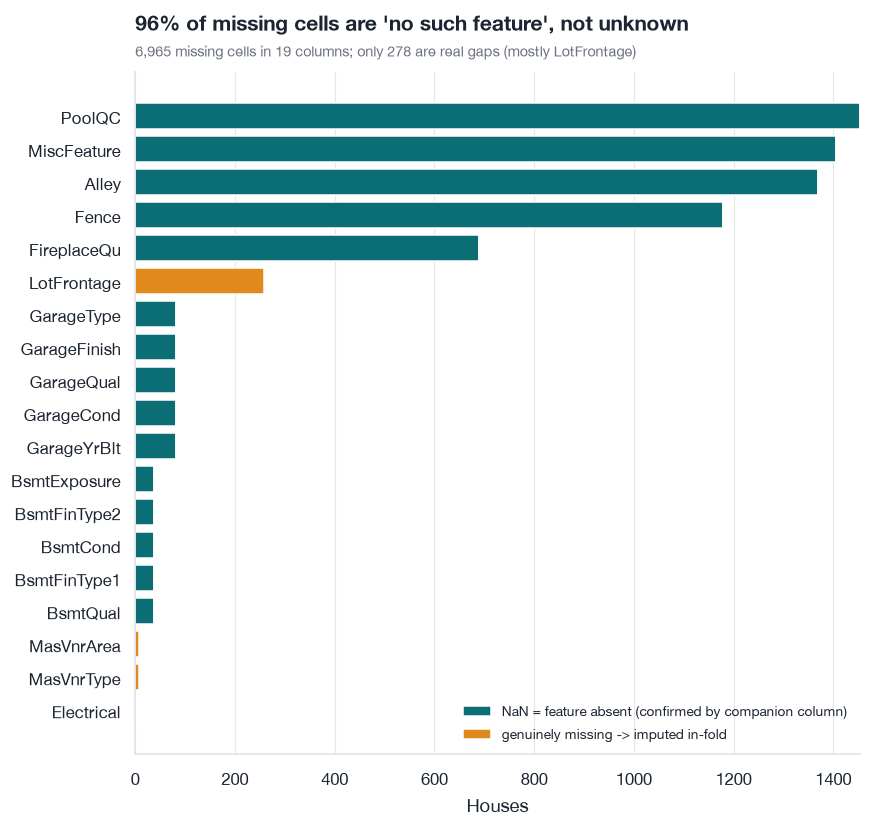

In [6]:
m = miss.iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 0.34 * len(m) + 1.6))
ax.barh(m.column, m.absence_confirmed, color=P.TEAL, label="NaN = feature absent (confirmed by companion column)")
ax.barh(m.column, m.genuinely_missing, left=m.absence_confirmed, color=P.AMBER, label="genuinely missing -> imputed in-fold")
ax.set_xlabel("Houses"); ax.grid(axis="y", visible=False); ax.legend(loc="lower right", fontsize=9)
true_missing = int(miss.genuinely_missing.sum()); total = int(miss.missing.sum())
P.headline(ax, f"{100*(1-true_missing/total):.0f}% of missing cells are 'no such feature', not unknown",
           f"{total:,} missing cells in {len(miss)} columns; only {true_missing:,} are real gaps (mostly LotFrontage)")
P.save_fig(fig, "eda_missingness"); plt.show()

In [7]:
# The few "real gaps" in basement/masonry/electrical columns are single rows, worth seeing explicitly:
odd = X.loc[(X.BsmtExposure.isna() & (X.TotalBsmtSF > 0)) | (X.BsmtFinType2.isna() & (X.TotalBsmtSF > 0)),
            ["TotalBsmtSF", "BsmtQual", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]]
display(Markdown("A basement exists (`TotalBsmtSF > 0`) yet one descriptor is blank, which is a data-entry gap, *not* 'no basement'. Our rule leaves these as NaN:"))
odd

A basement exists (`TotalBsmtSF > 0`) yet one descriptor is blank, which is a data-entry gap, *not* 'no basement'. Our rule leaves these as NaN:

,TotalBsmtSF,BsmtQual,BsmtExposure,BsmtFinType1,BsmtFinType2
332,3206,Gd,No,GLQ,NaN
948,936,Gd,NaN,Unf,Unf


**Is "absence" informative?** If so, the explicit `None` level (and the derived `Has*` flags) are real features rather than bookkeeping.

In [8]:
flags = {"Basement": X.TotalBsmtSF > 0, "Garage": X.GarageArea > 0, "Fireplace": X.Fireplaces > 0,
         "2nd floor": X["2ndFlrSF"] > 0, "Pool": X.PoolArea > 0}
tbl = pd.DataFrame({k: {"has": y[v].median(), "has not": y[~v].median(), "share with": v.mean()} for k, v in flags.items()}).T
tbl["premium_%"] = (100 * (tbl["has"] / tbl["has not"] - 1)).round(0)
tbl.assign(**{"has": tbl["has"].map("${:,.0f}".format), "has not": tbl["has not"].map("${:,.0f}".format),
              "share with": (100 * tbl["share with"]).round(1).astype(str) + " %"})

,has,has not,share with,premium_%
Basement,"$165,000","$101,800",97.5 %,62.0
Garage,"$167,500","$100,000",94.5 %,68.0
Fireplace,"$191,000","$135,000",52.7 %,41.0
2nd floor,"$177,000","$150,000",43.2 %,18.0
Pool,"$235,000","$162,900",0.5 %,44.0


## 3 · Where does the signal live?

Rank-correlation (Spearman) with log price over every numeric feature **after** the ordinal quality codes (`Ex > Gd > TA > Fa > Po > None`) have been turned into numbers by the project's feature builder. Spearman is robust to the outliers and non-linearity we see below.

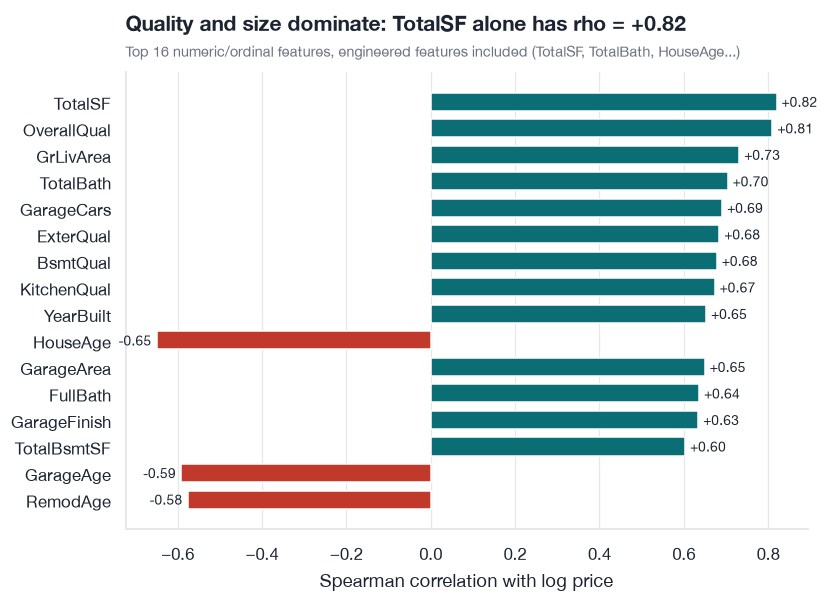

In [9]:
F = AmesFeatureBuilder().fit(X).transform(X)
num = F.select_dtypes("number")
corr = num.apply(lambda s: stats.spearmanr(s, np.log1p(y), nan_policy="omit").statistic).dropna()
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(16).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.4))
ax.barh(top.index, top.values, color=[P.TEAL if v > 0 else P.RED for v in top.values], height=0.68)
for i, v in enumerate(top.values):
    ax.text(v + (0.012 if v > 0 else -0.012), i, f"{v:+.2f}", va="center", ha="left" if v > 0 else "right", fontsize=9)
ax.grid(axis="y", visible=False); ax.set_xlabel("Spearman correlation with log price")
P.headline(ax, f"Quality and size dominate: {top.index[-1]} alone has rho = {top.values[-1]:+.2f}", "Top 16 numeric/ordinal features, engineered features included (TotalSF, TotalBath, HouseAge...)")
P.save_fig(fig, "eda_drivers"); plt.show()

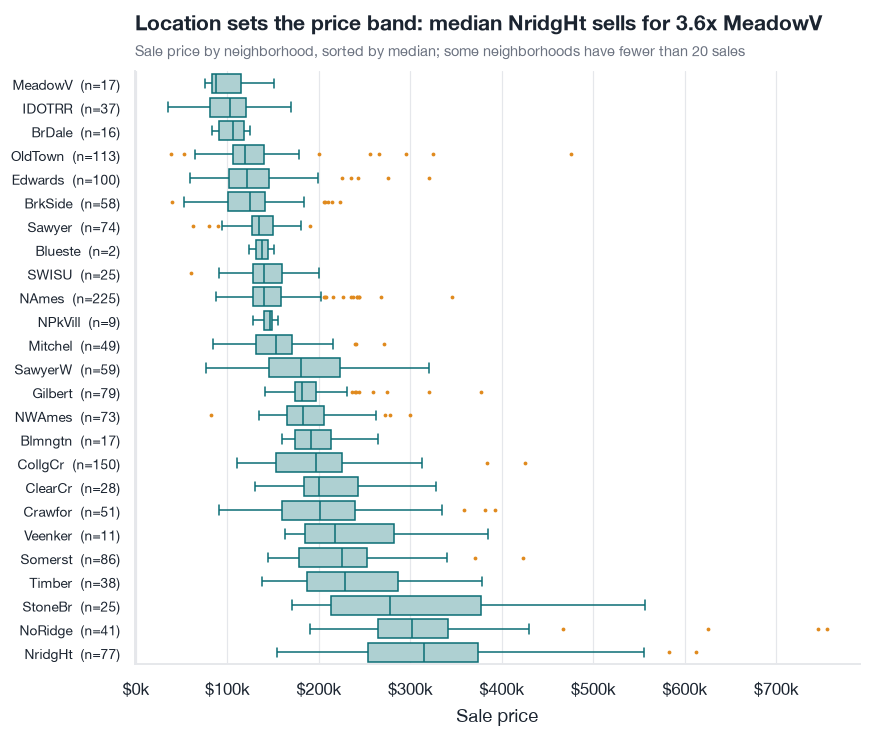

In [10]:
order = df.groupby("Neighborhood").SalePrice.median().sort_values()
counts = df.Neighborhood.value_counts()
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.boxplot(data=df, y="Neighborhood", x="SalePrice", order=order.index, color=P.TEAL_LIGHT, linecolor=P.TEAL,
            fliersize=2.5, flierprops={"markerfacecolor": P.AMBER, "markeredgecolor": "none"}, linewidth=1, ax=ax)
ax.set_yticklabels([f"{n}  (n={counts[n]})" for n in order.index], fontsize=9)
ax.xaxis.set_major_formatter(P.usd); ax.set_xlabel("Sale price"); ax.set_ylabel(""); ax.grid(axis="y", visible=False)
ratio = order.iloc[-1] / order.iloc[0]
P.headline(ax, f"Location sets the price band: median {order.index[-1]} sells for {ratio:.1f}x {order.index[0]}", "Sale price by neighborhood, sorted by median; some neighborhoods have fewer than 20 sales")
P.save_fig(fig, "eda_neighborhood"); plt.show()

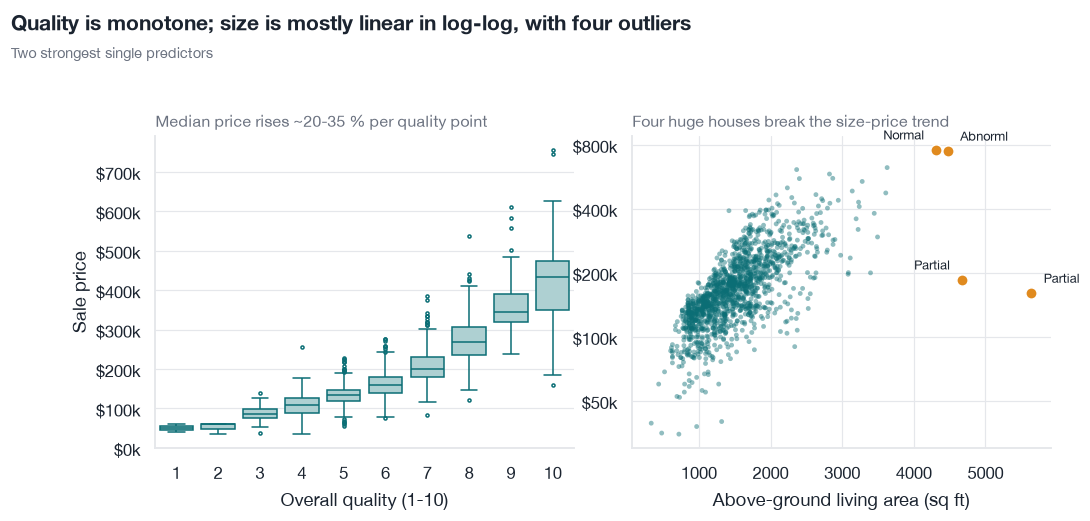

,Id,GrLivArea,OverallQual,SalePrice,SaleCondition,Neighborhood
523,524,4676,10,184750,Partial,Edwards
691,692,4316,10,755000,Normal,NoRidge
1182,1183,4476,10,745000,Abnorml,NoRidge
1298,1299,5642,10,160000,Partial,Edwards


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", color=P.TEAL_LIGHT, linecolor=P.TEAL, fliersize=2, linewidth=1, ax=axes[0])
axes[0].yaxis.set_major_formatter(P.usd); axes[0].set(xlabel="Overall quality (1-10)", ylabel="Sale price")
axes[0].set_title("Median price rises ~20-35 % per quality point", loc="left", fontsize=10.5, color=P.MUTED, fontweight="normal")
big = df.GrLivArea > 4000
axes[1].scatter(df.GrLivArea[~big], df.SalePrice[~big], s=10, alpha=0.45, color=P.TEAL, edgecolor="none")
axes[1].scatter(df.GrLivArea[big], df.SalePrice[big], s=55, color=P.AMBER, edgecolor="white", zorder=3)
for rank, (_, r) in enumerate(df[big].sort_values("GrLivArea").iterrows()):
    sign = -1 if rank % 2 == 0 else 1
    axes[1].annotate(f"{r.SaleCondition}", (r.GrLivArea, r.SalePrice), textcoords="offset points",
                     xytext=(8 * sign, 7), ha="right" if sign < 0 else "left", fontsize=8.5)
axes[1].set_yscale("log"); axes[1].yaxis.set_major_formatter(P.usd)
axes[1].yaxis.set_major_locator(plt.FixedLocator([50_000, 100_000, 200_000, 400_000, 800_000])); axes[1].yaxis.set_minor_formatter(plt.NullFormatter())
axes[1].set(xlabel="Above-ground living area (sq ft)", ylabel="")
axes[1].set_title("Four huge houses break the size-price trend", loc="left", fontsize=10.5, color=P.MUTED, fontweight="normal")
P.fig_headline(fig, "Quality is monotone; size is mostly linear in log-log, with four outliers", "Two strongest single predictors", y=0.99)
fig.subplots_adjust(top=0.82, wspace=0.14)
plt.show()
df.loc[big, ["Id", "GrLivArea", "OverallQual", "SalePrice", "SaleCondition", "Neighborhood"]]

## 4 · Data-quality traps

**Outliers.** Two of the four 4,000+ sq ft houses are `Partial` sales (house not yet completed when assessed) priced far below what their size suggests — the dataset's author himself recommends dropping them. We **keep them**: removing hard-to-predict rows from the evaluation data would flatter the metric. They will resurface in the error analysis (notebook 03).

**Time.** Sales span the 2008 housing crash. If the crash moved prices strongly, a random split would overstate performance for a model deployed in the future.

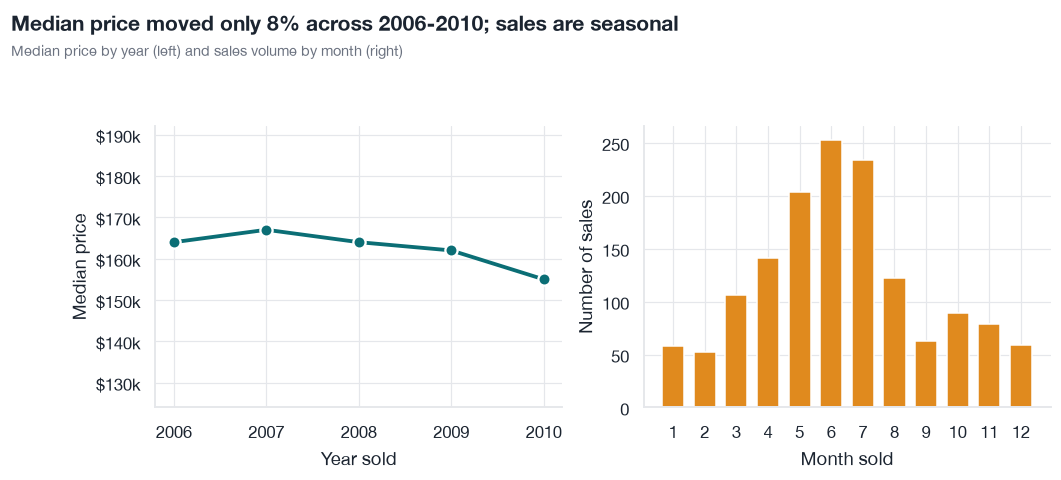

In [12]:
yr = df.groupby("YrSold").SalePrice.agg(["median", "count"])
mo = df.groupby("MoSold").SalePrice.agg(["median", "count"])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
axes[0].plot(yr.index, yr["median"], "o-", color=P.TEAL, lw=2.5, ms=8, mec="white", mew=1.5)
axes[0].yaxis.set_major_formatter(P.usd); axes[0].set_xticks(yr.index); axes[0].set(xlabel="Year sold", ylabel="Median price", ylim=(0.8 * yr["median"].min(), 1.15 * yr["median"].max()))
axes[1].bar(mo.index, mo["count"], color=P.AMBER, width=0.7); axes[1].set(xlabel="Month sold", ylabel="Number of sales"); axes[1].set_xticks(range(1, 13))
P.fig_headline(fig, f"Median price moved only {100*(yr['median'].max()/yr['median'].min()-1):.0f}% across 2006-2010; sales are seasonal", "Median price by year (left) and sales volume by month (right)", y=0.99)
fig.subplots_adjust(top=0.82, wspace=0.2)
plt.show()

## Takeaways that shape the modelling

| Finding | Consequence |
|---|---|
| Price is right-skewed, error is proportional | Fit on `log1p(price)`; report RMSLE |
| ~96 % of NaNs mean "feature absent" | Explicit `None` level where a companion column confirms it; impute the rest **inside CV folds** |
| Quality + size + neighborhood dominate | Add `TotalSF`, `TotalBath`, ages, `Has*` flags; ordinal-encode quality grades; give trees a good neighborhood encoding |
| Four outliers, two of them partial sales | Keep, and report error by segment |
| Crash years, but modest median movement; all sales are 2006-2010 in one city | Random CV is defensible, but results are **not** a forecast for other markets or times (see limitations) |

Next: `02_modeling.ipynb`.

In [13]:
elapsed = time.perf_counter() - T0
import json
config.RESULTS_DIR.mkdir(parents=True, exist_ok=True)
rt_path = config.RESULTS_DIR / "runtimes.json"
rt = json.loads(rt_path.read_text()) if rt_path.exists() else {}
rt["01_eda_seconds"] = round(elapsed, 1)
rt_path.write_text(json.dumps(rt, indent=2))
print(f"notebook runtime: {elapsed:.1f}s")

notebook runtime: 2.4s
